# ViT-based Image Classification with CIFAR-10 Dataset

본 노트북은 자연어 처리(NLP) 분야에서 혁신을 일으킨 **Transformer 아키텍처**를 컴퓨터 비전(Computer Vision) 도메인에 직접 적용한 **Vision Transformer (ViT)** 모델을 PyTorch로 밑바닥부터(From Scratch) 구현하고, 이를 활용하여 **CIFAR-10 데이터셋(10개 클래스 컬러 이미지)**을 분류하는 전체 과정을 다룹니다.

---

### 전체 파이프라인 요약
1. **런타임 및 시각화 환경 설정**: GPU 가속 장치(`cuda`) 확인, 한글 폰트 설정 및 아키텍처 블록 다이어그램 시각화 함수(`draw_blocks`)를 정의합니다.
2. **데이터셋 준비 및 전처리**: CIFAR-10 데이터셋을 로드하고 학습용 데이터 증강(Data Augmentation), 정규화(Normalization), 학습/검증/테스트 데이터 분할(`45,000 / 5,000 / 10,000`) 및 `DataLoader` 구성을 수행합니다.
3. **Vision Transformer 모델 구현**:
   - **`img_to_patch`**: $32 \times 32$ 이미지를 $4 \times 4$ 크기의 패치(Patch) 64개로 분할하고 1차원 벡터($48$차원)로 평탄화(Flatten)합니다.
   - **`AttentionBlock`**: Pre-Layer Normalization(Pre-LN) 구조 기반의 Multi-Head Self-Attention(MSA) 및 MLP 블록과 잔차 연결(Residual Connection)을 구현합니다.
   - **`VisionTransformer`**: 패치 선형 투영(Linear Projection), 학습 가능한 `[CLS]` 토큰 결합, 위치 임베딩(Positional Embedding) 합산, 6층 인코더 통과 및 최종 분류 헤드(Classification Head)를 조립합니다.
4. **모델 학습 및 검증**: `CrossEntropyLoss`, `AdamW` 옵티마이저, `MultiStepLR` 학습률 스케줄러를 사용하여 12 에폭(Epoch) 동안 학습을 진행하고 최고 검증 정확도 모델을 저장합니다.
5. **최종 테스트 및 예측 결과 확인**: 저장된 최적 가중치를 로드하여 테스트 데이터셋(10,000장)에 대한 최종 성능을 평가하고 샘플 이미지의 예측 결과를 시각적으로 확인합니다.


## 1. 런타임 환경 및 시각화 유틸리티 설정

본격적인 데이터 로드와 모델 구현에 앞서 다음과 같은 초기 설정을 수행합니다.
- **하드웨어 가속 장치(`DEVICE`) 설정**: GPU(`cuda`) 사용 가능 여부를 확인하여 연산 장치를 지정합니다.
- **한글 폰트 설치 및 등록(`hangul_font`)**: Linux/Colab 환경에서 그래프 내 한글 제목이나 설명이 깨지는 현상(두부 현상)을 방지하기 위해 `NotoSansCJK` 및 `NanumGothic` 폰트를 설치하고 `matplotlib`에 등록합니다.
- **시각화 도우미 함수 정의**:
  - `show_img`: PIL 이미지의 가로 폭을 조정하여 Jupyter 출력 셀에 깔끔하게 표시합니다.
  - `draw_blocks`: 모델의 텐서 흐름과 블록 구조를 직관적으로 이해할 수 있도록 박스(`FancyBboxPatch`)와 화살표(`FancyArrowPatch`, 잔차 연결용 점선 곡선 포함)로 다이어그램을 그려주는 커스텀 함수입니다.


In [1]:
# 메모리 버퍼 처리 및 파일 시스템 경로 제어를 위한 표준 라이브러리를 임포트합니다.
from io import BytesIO
from pathlib import Path

# 딥러닝 프레임워크 PyTorch 및 컴퓨터 비전용 Torchvision 라이브러리를 임포트합니다.
import torch
import torchvision

# 노트북 환경에서의 이미지 출력 및 그래픽/시각화 처리를 위한 모듈들을 임포트합니다.
from IPython.display import display
from PIL import Image, ImageFont
from matplotlib import font_manager, pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from torch import nn
from torchvision import transforms
from torchvision.datasets import CIFAR10

# GPU(CUDA)가 사용 가능한 경우 'cuda'를, 그렇지 않으면 'cpu'를 연산 장치로 설정합니다.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__)
print("device", DEVICE)
if DEVICE.type == "cuda":
    # 연결된 첫 번째 GPU의 모델명을 출력합니다.
    print("gpu", torch.cuda.get_device_name(0))

# 리눅스(Colab 등) 환경에서 그래프 내 한글 출력을 지원하기 위해 한글 폰트 패키지를 설치합니다.
!apt-get -qq update
!apt-get -qq install -y fonts-noto-cjk fonts-nanum


def hangul_font(size=14):
    """시스템에 설치된 한글 폰트 경로를 탐색하여 PIL 및 Matplotlib의 기본 폰트로 설정합니다."""
    # 우선순위에 따라 탐색할 한글 폰트 파일 경로와 폰트 컬렉션 인덱스 목록입니다.
    for path, index in (
        ("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/nanum/NanumGothic.ttf", None),
    ):
        # 해당 경로에 폰트 파일이 존재하지 않으면 다음 후보로 넘어갑니다.
        if not Path(path).exists():
            continue
        try:
            # .ttc 파일인 경우 index 인자를 전달하여 한글 폰트를 로드합니다.
            kw = {"index": index} if index is not None else {}
            font = ImageFont.truetype(path, size, **kw)
            try:
                # Matplotlib의 폰트 매니저에 해당 폰트를 추가하고 기본 font.family로 지정합니다.
                font_manager.fontManager.addfont(path)
                plt.rcParams["font.family"] = font_manager.FontProperties(fname=path).get_name()
            except (OSError, ValueError, RuntimeError):
                pass
            print("hangul_font", path)
            return font
        except OSError:
            continue
    print("hangul_font missing")
    return None


# 한글 폰트 설정을 적용하고, 음수 기호('-')가 깨지지 않도록 설정합니다.
hangul_font()
plt.rcParams["axes.unicode_minus"] = False


def show_img(img, width=900):
    """PIL 이미지를 지정된 최대 가로 폭(width)에 맞춰 비율을 유지하며 리사이즈한 뒤 화면에 출력합니다."""
    img = img.convert("RGB")
    w, h = img.size
    # 이미지의 가로 길이가 지정된 width보다 크면 종횡비를 유지하여 축소합니다.
    if w > width:
        img = img.resize((width, int(h * width / w)), Image.BILINEAR)
    display(img)


def draw_blocks(title, nodes, arrows=(), note="", figsize=(12.2, 3.0)):
    """모델 아키텍처의 각 단계(노드)와 텐서 흐름(화살표, 잔차 연결 포함)을 블록 다이어그램으로 시각화합니다."""
    fig, ax = plt.subplots(figsize=figsize)
    boxes = {}

    # 1. 각 노드(블록)를 둥근 모서리 사각형(FancyBboxPatch)으로 그리고 내부 텍스트를 배치합니다.
    for n in nodes:
        bw, bh = n.get("bw", 1.85), n.get("bh", 1.12)  # 박스의 가로(bw), 세로(bh) 크기
        cx, cy = n["cx"], n["cy"]                      # 박스의 중심 좌표 (cx, cy)
        ax.add_patch(
            FancyBboxPatch(
                (cx - bw / 2, cy - bh / 2),
                bw,
                bh,
                boxstyle="round,pad=0.02,rounding_size=0.08",
                facecolor=n.get("color", "#ececec"),
                edgecolor="#222",
                linewidth=1.1,
            )
        )
        # 박스 상단에는 굵은 제목(title)을, 하단에는 텐서 형태 등의 부제목(sub)을 표시합니다.
        ax.text(cx, cy + 0.20, n["title"], ha="center", va="center", fontsize=8.2, fontweight="bold")
        ax.text(cx, cy - 0.22, n["sub"], ha="center", va="center", fontsize=7.2, color="#333")
        boxes[n["key"]] = (cx, cy, bw, bh)

    # 2. 전체 노드들의 좌표를 기준으로 그래프의 X축, Y축 여백을 자동 설정합니다.
    xs, ys = [], []
    for cx, cy, bw, bh in boxes.values():
        xs += [cx - bw / 2, cx + bw / 2]
        ys += [cy - bh / 2, cy + bh / 2]
    ax.set_xlim(min(xs) - 0.35, max(xs) + 0.35)
    ax.set_ylim(min(ys) - 0.75, max(ys) + 0.9)
    ax.axis("off")
    ax.set_title(title, fontsize=13, pad=8)

    # 3. 노드 간을 연결하는 화살표(일반 직선 화살표 및 잔차 연결용 아치형 점선 화살표)를 그립니다.
    for item in arrows:
        src, dst = item[0], item[1]
        text = item[2] if len(item) > 2 else ""
        style = item[3] if len(item) > 3 else "plain"
        x1, y1, w1, h1 = boxes[src]
        x2, y2, w2, h2 = boxes[dst]
        skip = style == "skip"  # 잔차 연결(Residual Skip Connection) 여부 확인
        color = "#c05621" if skip else "#333"
        dx = x2 - x1
        dy = y2 - y1

        if skip:
            # 잔차 연결인 경우 박스 상단을 가로지르는 곡선(arc3) 점선 화살표로 표현합니다.
            patch = FancyArrowPatch(
                (x1, y1 + h1 / 2),
                (x2, y2 + h2 / 2),
                arrowstyle="-|>",
                mutation_scale=10,
                lw=1.25,
                color=color,
                connectionstyle="arc3,rad=0.42",
                linestyle=(0, (4, 3)),
            )
        elif abs(dx) >= abs(dy):
            # 수평 방향 이동이 주를 이루는 경우 좌우 테두리를 연결합니다.
            x_s = x1 + w1 / 2 + 0.02 if dx > 0 else x1 - w1 / 2 - 0.02
            x_e = x2 - w2 / 2 - 0.02 if dx > 0 else x2 + w2 / 2 + 0.02
            patch = FancyArrowPatch((x_s, y1), (x_e, y2), arrowstyle="-|>", mutation_scale=10, lw=1.25, color=color)
        else:
            # 수직 방향 이동이 주를 이루는 경우 상하 테두리를 연결합니다.
            y_s = y1 - h1 / 2 - 0.02 if dy < 0 else y1 + h1 / 2 + 0.02
            y_e = y2 + h2 / 2 + 0.02 if dy < 0 else y2 - h2 / 2 - 0.02
            patch = FancyArrowPatch((x1, y_s), (x2, y_e), arrowstyle="-|>", mutation_scale=10, lw=1.25, color=color)
        ax.add_patch(patch)
        if text:
            ax.text((x1 + x2) / 2, max(y1, y2) + (0.78 if skip else 0.62), text, ha="center", fontsize=7, color="#444")

    # 4. 하단 부연 설명(note)이 있는 경우 표시하고 이미지를 버퍼에 저장한 뒤 출력합니다.
    if note:
        ax.text((min(xs) + max(xs)) / 2, min(ys) - 0.45, note, ha="center", fontsize=8, color="#333")
    fig.tight_layout()
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    buf.seek(0)
    show_img(Image.open(buf), width=980)


torch 2.11.0+cu130
device cuda
gpu Tesla T4
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-nanum.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Selecting previously unselected package fonts-noto-cjk.
Preparing to unpack .../fonts-noto-cjk_1%3a20230817+repack1-3_all.deb ...
Unpacking fonts-noto-cjk (1:20230817+repack1-3) ...
Setting up fonts-nanum (20200506-1) ...
Setting up fonts-noto-cjk (1:20230817+repack1-3) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
hangul_font /usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc


### Vision Transformer (ViT)의 핵심 개념

이미지를 다루는 딥러닝 방법론 중 합성곱 신경망(CNN)과 더불어 가장 널리 쓰이는 아키텍처는 **Vision Transformer (ViT)**입니다.

1. **패치 토큰화 (Patch Tokenization)**:
   - CNN이 로컬 필터(커널)를 슬라이딩하며 특징을 추출하는 것과 달리, ViT는 2차원 이미지를 겹치지 않는 작은 사각형 조각인 **패치(Patch)** 단위로 자른 뒤 일렬(1D 시퀀스)로 나열하여 자연어 문장의 '단어 토큰(Token)'처럼 취급합니다.
   - 본 실습에서 사용하는 **CIFAR-10** 데이터셋은 가로·세로 $32 \times 32$ 크기의 RGB 컬러 이미지($C=3$)이며 총 10개의 클래스로 구성됩니다.
   - 패치 한 변의 크기(`PATCH`)를 $4$로 설정하면 가로 $32 / 4 = 8$칸, 세로 $32 / 4 = 8$칸으로 나뉘므로, 이미지 1장당 총 **$N = 8 \times 8 = 64$개의 패치 토큰**이 생성됩니다.
2. **분류용 `[CLS]` 토큰과 트랜스포머 인코더**:
   - 64개의 패치 토큰을 선형 레이어(`Linear`)에 통과시켜 임베딩 차원(`EMBED_DIM = 256`)으로 투영한 뒤, 시퀀스 맨 앞에 이미지 전체의 전역 정보를 집약할 학습 가능한 **`[CLS]` (Classification) 토큰** 1개를 덧붙여 총 **65개의 토큰 시퀀스**를 만듭니다.
   - 여기에 각 패치의 위치 정보를 알려주는 **위치 임베딩(Positional Embedding)**을 더한 후, 트랜스포머 인코더(Self-Attention + MLP) 블록을 여러 층 통과시켜 모든 패치 토큰 간의 상호 관계(전역 문맥)를 학습합니다.
   - 마지막으로 인코더를 통과한 맨 앞의 `[CLS]` 토큰 벡터만 추출하여 선형 분류기(`Linear`)에 입력함으로써 10개 클래스에 대한 예측 점수(Logits)를 산출합니다.


## 2. 데이터셋 준비 및 하이퍼파라미터 설정


### 데이터 분할 및 전처리(Augmentation & Normalization) 전략

- **데이터 분할**: CIFAR-10의 원본 학습용 이미지 50,000장 중 **45,000장은 모델 학습(Train)**에 사용하고, 나머지 **5,000장은 검증(Validation)**용으로 분리하여 에폭별 최고 성능 모델을 선택하는 기준으로 삼습니다. 별도로 제공되는 **10,000장의 테스트(Test) 데이터**는 모든 학습이 끝난 뒤 최종 일반화 성능을 평가할 때만 사용합니다.
- **데이터 증강(Data Augmentation)**: ViT는 CNN에 비해 귀납적 편향(Inductive Bias, 예: 지역성 및 평행이동 불변성)이 약하기 때문에 과적합(Overfitting)되기 쉽습니다. 이를 완화하기 위해 학습 데이터(`train_transform`)에는 **무작위 좌우 반전(`RandomHorizontalFlip`)**과 **무작위 크롭 후 리사이즈(`RandomResizedCrop`)**를 적용합니다.
- **정규화(Normalization)**: 모든 이미지 텐서에 대해 CIFAR-10 학습 세트의 RGB 채널별 평균(`CIFAR_MEAN`)을 빼고 표준편차(`CIFAR_STD`)로 나누어 학습 안정성을 높입니다.
- **동일 시드(`manual_seed(42)`) 분할 트릭**: 학습 세트에는 데이터 증강을 적용하고 검증 세트에는 증강을 적용하지 않기 위해, 서로 다른 `transform`이 적용된 `train_dataset`과 `val_dataset` 객체를 각각 생성한 뒤 동일한 난수 시드(`42`)로 `random_split`을 수행하여 인덱스가 서로 겹치지 않게 정확히 분리합니다.


100%|██████████| 170M/170M [1:02:39<00:00, 45.4kB/s]


train 45000 val 5000 test 10000
patch 4 토큰 64 클래스 10


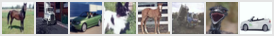

In [2]:
# =========================================================
# 1. 모델 아키텍처 및 학습 하이퍼파라미터 정의
# =========================================================
IMG_SIZE = 32                        # 입력 이미지의 가로/세로 해상도 (32x32)
PATCH = 4                            # 개별 패치의 가로/세로 크기 (4x4)
N_PATCHES = (IMG_SIZE // PATCH) ** 2 # 이미지 1장당 생성되는 총 패치(토큰) 수: (32 // 4)^2 = 64개
EMBED_DIM = 256                      # 트랜스포머 내부 토큰 임베딩 벡터의 차원 수 (D)
HIDDEN_DIM = 512                     # 트랜스포머 블록 내 MLP(Feed-Forward) 은닉층 차원 수
N_HEADS = 8                          # Multi-Head Self-Attention의 어텐션 헤드 개수 (헤드당 차원: 256 // 8 = 32)
N_LAYERS = 6                         # 스태킹할 AttentionBlock(인코더 레이어)의 총 층수
NUM_CLASSES = 10                     # 분류할 타겟 클래스 개수 (CIFAR-10은 10개 범주)
DROPOUT = 0.2                        # 과적합 방지를 위한 드롭아웃(Dropout) 비율
BATCH = 128                          # 미니배치(Mini-batch) 크기
LR = 3e-4                            # AdamW 옵티마이저의 초기 학습률 (Learning Rate)
EPOCHS = 12                          # 전체 데이터셋 반복 학습 횟수 (Epochs)

# CIFAR-10 데이터셋의 RGB 채널별 평균 및 표준편차 상수 (정규화용)
CIFAR_MEAN = [0.49139968, 0.48215841, 0.44653091]
CIFAR_STD = [0.24703223, 0.24348513, 0.26158784]

# CIFAR-10의 10개 클래스 영문 레이블 이름 정의
CLASSES = (
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
)

# Colab 환경(/content 존재 시) 또는 로컬 작업 디렉터리에 데이터 저장 경로를 지정합니다.
DATA_ROOT = Path("/content/cifar10") if Path("/content").exists() else Path.cwd() / "cifar10"

# =========================================================
# 2. 이미지 전처리 및 데이터 증강 파이프라인 정의
# =========================================================
# 학습용 변환: 좌우 뒤집기 및 무작위 크롭/리사이즈 증강 후 텐서 변환 및 정규화를 수행합니다.
train_transform = transforms.Compose(
    [
        transforms.RandomHorizontalFlip(),
        transforms.RandomResizedCrop((IMG_SIZE, IMG_SIZE), scale=(0.8, 1.0), ratio=(0.9, 1.1)),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
    ]
)

# 검증 및 테스트용 변환: 데이터 증강 없이 텐서 변환 및 정규화만 수행하여 일관된 평가를 보장합니다.
eval_transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
    ]
)

# =========================================================
# 3. 데이터셋 다운로드 및 학습/검증/테스트 분할
# =========================================================
train_dataset = CIFAR10(root=DATA_ROOT, train=True, transform=train_transform, download=True)
val_dataset = CIFAR10(root=DATA_ROOT, train=True, transform=eval_transform, download=True)
test_set = CIFAR10(root=DATA_ROOT, train=False, transform=eval_transform, download=True)

# 동일한 시드(42)를 가진 난수 생성기를 사용하여 50,000장을 45,000장(train)과 5,000장(val)으로 상호 배타적이게 분할합니다.
gen = torch.Generator().manual_seed(42)
train_set, _ = torch.utils.data.random_split(train_dataset, [45000, 5000], generator=gen)
gen = torch.Generator().manual_seed(42)
_, val_set = torch.utils.data.random_split(val_dataset, [45000, 5000], generator=gen)

# =========================================================
# 4. 미니배치 단위로 데이터를 공급하는 DataLoader 생성
# =========================================================
train_loader = torch.utils.data.DataLoader(
    train_set,
    batch_size=BATCH,
    shuffle=True,                     # 에폭마다 데이터 순서를 무작위로 섞습니다.
    drop_last=True,                   # 마지막 남는 자투리 배치는 버려 배치 크기를 일정하게 유지합니다.
    num_workers=2,                    # 데이터 로딩에 사용할 서브 프로세스 수
    pin_memory=DEVICE.type == "cuda", # GPU 사용 시 고정 메모리(Pinned Memory)를 활성화하여 전송 속도를 높입니다.
)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=BATCH, shuffle=False, num_workers=2)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=BATCH, shuffle=False, num_workers=2)

print("train", len(train_set), "val", len(val_set), "test", len(test_set))
print("patch", PATCH, "토큰", N_PATCHES, "클래스", NUM_CLASSES)

# 검증 데이터셋에서 첫 8장의 이미지를 추출하여 그리드 형태로 미리보기 시각화를 수행합니다.
preview = torch.stack([val_set[i][0] for i in range(8)])
grid = torchvision.utils.make_grid(preview, nrow=8, normalize=True, pad_value=0.9)
show_img(transforms.functional.to_pil_image(grid), width=980)


## 3. Vision Transformer (ViT) 모델 아키텍처 구현

아래 다이어그램은 입력 이미지 텐서 `(B, 3, 32, 32)`가 ViT 파이프라인을 거쳐 최종 클래스 예측 로짓 `(B, 10)`으로 변환되는 전체 과정을 한눈에 보여줍니다.

1. **입력 이미지 (`image`)**: 배치 크기 $B$, 채널 $3$(RGB), 해상도 $32 \times 32$인 텐서 `(B, 3, 32, 32)`가 입력됩니다.
2. **패치 분할 (`img_to_patch`)**: $4 \times 4$ 크기로 이미지를 잘라 $N=64$개의 패치로 만들고 각 패치의 픽셀값($3 \times 4 \times 4 = 48$)을 펼쳐 `(B, 64, 48)` 텐서로 변환합니다.
3. **선형 투영 (`Linear`)**: 각 패치의 48차원 벡터를 트랜스포머의 임베딩 차원인 256차원으로 매핑하여 `(B, 64, 256)`을 만듭니다.
4. **`[CLS]` 토큰 결합 및 위치 임베딩 (`+ CLS, pos`)**: 시퀀스 맨 앞에 학습 가능한 `[CLS]` 토큰 1개를 추가하여 토큰 수를 65개로 늘리고, 각 위치의 고유 정보를 담은 위치 임베딩을 더해 `(B, 65, 256)`을 구성합니다.
5. **트랜스포머 인코더 (`Encoder ×6`)**: Multi-Head Self-Attention과 MLP로 구성된 인코더 블록을 6회 연속 통과하며 패치 간의 전역적 상호작용을 계산합니다.
6. **분류 헤드 (`CLS Linear`)**: 인코더 출력 중 첫 번째 위치인 `[CLS]` 토큰 벡터 `(B, 256)`만 뽑아내어 `LayerNorm`과 `Linear(256 → 10)`를 거쳐 최종 클래스 점수 `(B, 10)`을 출력합니다.


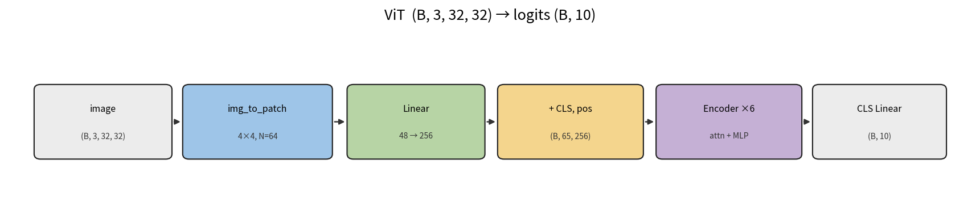

In [3]:
# 전체 ViT 파이프라인의 단계별 텐서 형태 변화를 블록 다이어그램으로 시각화합니다.
draw_blocks(
    "ViT  (B, 3, 32, 32) → logits (B, 10)",
    [
        {"key": "in", "cx": 1.0, "cy": 1.3, "title": "image", "sub": "(B, 3, 32, 32)", "color": "#ececec", "bw": 1.7},
        {"key": "pt", "cx": 2.95, "cy": 1.3, "title": "img_to_patch", "sub": "4×4, N=64", "color": "#9ec5e8", "bw": 1.85},
        {"key": "lin", "cx": 4.95, "cy": 1.3, "title": "Linear", "sub": "48 → 256", "color": "#b7d4a5", "bw": 1.7},
        {"key": "cls", "cx": 6.9, "cy": 1.3, "title": "+ CLS, pos", "sub": "(B, 65, 256)", "color": "#f4d58d", "bw": 1.8},
        {"key": "enc", "cx": 8.9, "cy": 1.3, "title": "Encoder ×6", "sub": "attn + MLP", "color": "#c5b0d5", "bw": 1.8},
        {"key": "out", "cx": 10.8, "cy": 1.3, "title": "CLS Linear", "sub": "(B, 10)", "color": "#ececec", "bw": 1.65},
    ],
    [("in", "pt"), ("pt", "lin"), ("lin", "cls"), ("cls", "enc"), ("enc", "out")],
    figsize=(12.4, 2.8),
)


### 3-1. 이미지를 패치 시퀀스로 변환하기 (`img_to_patch`)

`img_to_patch` 함수는 4차원 이미지 텐서 `(B, C, H, W)`를 입력받아 겹치지 않는 작은 격자 패치들로 분할하고 시퀀스 형태로 재배열합니다.

- **차원 변환 단계별 상세 과정** ($B$: 배치 크기, $C=3$, $H=32$, $W=32$, $P=4$ 기준):
  1. **입력(`x`)**: `(B, 3, 32, 32)`
  2. **`reshape`**: 높이와 너비 축을 각각 `(패치 개수, 패치 크기)`로 쪼갭니다 $\rightarrow$ `(B, 3, 8, 4, 8, 4)`
  3. **`permute(0, 2, 4, 1, 3, 5)`**: 세로·가로 격자 위치 인덱스인 `8, 8`을 앞쪽으로 이동시키고, 패치 내부 데이터인 `3, 4, 4`를 뒤쪽으로 모읍니다 $\rightarrow$ `(B, 8, 8, 3, 4, 4)`
  4. **`flatten(1, 2)`**: 2차원 격자(`8×8`)를 1차원 토큰 시퀀스(`64`)로 펼칩니다 $\rightarrow$ `(B, 64, 3, 4, 4)`
  5. **`flatten(2, 4)`** (`flatten_channels=True`일 때): 각 패치의 채널과 가로·세로 픽셀(`3×4×4`)을 하나의 1차원 특징 벡터(`48`)로 평탄화합니다 $\rightarrow$ **`(B, 64, 48)`**


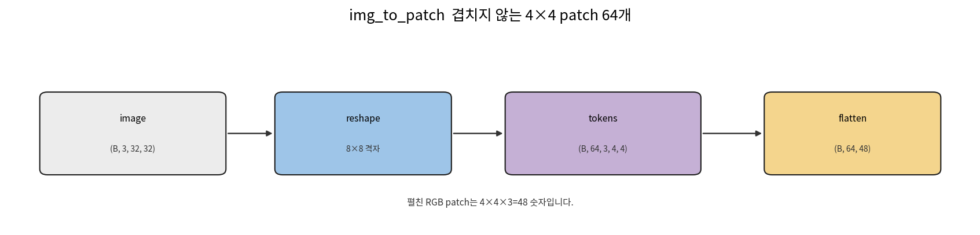

image (2, 3, 32, 32) tokens (2, 64, 48)


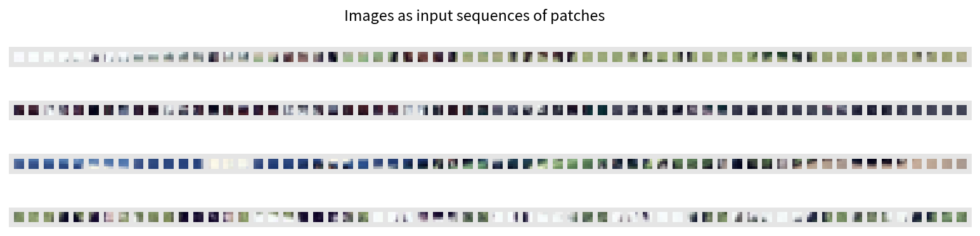

In [4]:
def img_to_patch(x, patch_size, flatten_channels=True):
    """
    입력 이미지 텐서를 겹치지 않는 패치(Patch) 시퀀스로 분할합니다.

    Args:
        x (torch.Tensor): (B, C, H, W) 형태의 입력 이미지 배치 텐서
        patch_size (int): 단일 정사각형 패치의 한 변 길이 (P)
        flatten_channels (bool): True이면 각 패치의 (C, P, P)를 1차원 벡터(C*P*P)로 평탄화합니다.
                                 시각화 목적으로 패치 이미지를 유지하려면 False로 지정합니다.
    Returns:
        torch.Tensor: (B, N_patches, C*P*P) 또는 (B, N_patches, C, P, P) 형태의 패치 시퀀스 텐서
    """
    batch, channels, height, width = x.shape

    # 1. 높이(H)와 너비(W) 차원을 (격자 개수, 패치 크기) 형태로 분할합니다. -> (B, C, H//P, P, W//P, P)
    x = x.reshape(batch, channels, height // patch_size, patch_size, width // patch_size, patch_size)

    # 2. 패치의 격자 좌표(H//P, W//P) 차원을 채널(C) 앞으로 이동시킵니다. -> (B, H//P, W//P, C, P, P)
    x = x.permute(0, 2, 4, 1, 3, 5)

    # 3. 2차원 격자(H//P, W//P)를 하나의 시퀀스 차원(N_patches = 64)으로 평탄화합니다. -> (B, 64, C, P, P)
    x = x.flatten(1, 2)

    # 4. 모델 입력용으로 사용할 때는 각 패치 내부의 (C, P, P) 픽셀들을 단일 벡터(48차원)로 펼칩니다. -> (B, 64, 48)
    if flatten_channels:
        x = x.flatten(2, 4)
    return x


# img_to_patch 함수의 내부 텐서 변환 과정을 다이어그램으로 시각화합니다.
draw_blocks(
    "img_to_patch  겹치지 않는 4×4 patch 64개",
    [
        {"key": "im", "cx": 1.3, "cy": 1.3, "title": "image", "sub": "(B, 3, 32, 32)", "color": "#ececec", "bw": 1.9},
        {"key": "cut", "cx": 3.7, "cy": 1.3, "title": "reshape", "sub": "8×8 격자", "color": "#9ec5e8", "bw": 1.8},
        {"key": "tok", "cx": 6.2, "cy": 1.3, "title": "tokens", "sub": "(B, 64, 3, 4, 4)", "color": "#c5b0d5", "bw": 2.0},
        {"key": "flat", "cx": 8.8, "cy": 1.3, "title": "flatten", "sub": "(B, 64, 48)", "color": "#f4d58d", "bw": 1.8},
    ],
    [("im", "cut"), ("cut", "tok"), ("tok", "flat")],
    note="펼친 RGB patch는 4×4×3=48 숫자입니다.",
)

# 더미 텐서(배치 크기 2)를 입력하여 출력 텐서의 형태가 (2, 64, 48)이 되는지 검증합니다.
x = torch.zeros(2, 3, IMG_SIZE, IMG_SIZE)
print("image", tuple(x.shape), "tokens", tuple(img_to_patch(x, PATCH).shape))

# 검증 세트의 샘플 이미지 4장을 실제로 64개의 패치 조각으로 잘라 일렬로 나열한 모습을 시각화합니다.
sample = torch.stack([val_set[i][0] for i in range(4)])
patches = img_to_patch(sample, PATCH, flatten_channels=False)  # 시각화를 위해 (3, 4, 4) 형태 유지
fig, axes = plt.subplots(patches.size(0), 1, figsize=(14, 3))
fig.suptitle("Images as input sequences of patches")
for i in range(patches.size(0)):
    grid = torchvision.utils.make_grid(patches[i], nrow=N_PATCHES, normalize=True, pad_value=0.9)
    axes[i].imshow(grid.permute(1, 2, 0).cpu())
    axes[i].axis("off")
buf = BytesIO()
fig.savefig(buf, format="png", dpi=140, bbox_inches="tight", facecolor="white")
plt.close(fig)
buf.seek(0)
show_img(Image.open(buf), width=980)


### 3-2. 트랜스포머 인코더 블록 (`AttentionBlock`)

`AttentionBlock` 클래스는 ViT의 핵심 연산 단위인 **Pre-Norm (Pre-Layer Normalization)** 구조의 트랜스포머 인코더 레이어입니다.

- **Pre-Norm 구조의 특징**:
  - 초기 트랜스포머(Post-Norm)와 달리, 어텐션(`MultiheadAttention`)과 피드포워드 네트워크(`MLP`)에 들어가기 **직전에 `LayerNorm`을 먼저 적용**하고, 서브 레이어의 출력을 원본 입력(`x`)에 그대로 더하는 **잔차 연결(Residual Connection)**을 수행합니다.
  - 수식으로 표현하면 다음과 같습니다:
    $$\mathbf{z}' = \mathbf{x} + \text{MSA}(\text{LayerNorm}_1(\mathbf{x}))$$
    $$\mathbf{y} = \mathbf{z}' + \text{MLP}(\text{LayerNorm}_2(\mathbf{z}'))$$
  - 이 방식은 역전파 시 그래디언트가 잔차 경로(Skip Connection)를 통해 막힘없이 흐르도록 도와주어 깊은 층을 쌓아도 학습이 매우 안정적입니다.
- **텐서 차원 순서 주의 (`(Seq_Len, Batch, Embed_Dim)`)**:
  - PyTorch의 `nn.MultiheadAttention`은 기본적으로 `batch_first=False`로 동작하므로, 입력 텐서의 첫 번째 차원이 시퀀스 길이(토큰 개수 `65`), 두 번째 차원이 배치 크기(`B`), 세 번째 차원이 임베딩 차원(`256`)인 `(65, B, 256)` 형태를 사용합니다.


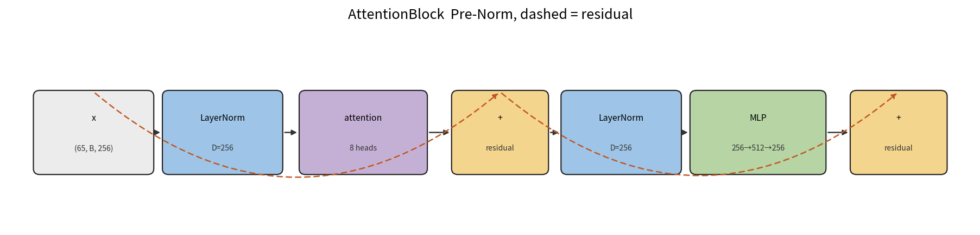

x (65, 2, 256) out (65, 2, 256)


In [5]:
class AttentionBlock(nn.Module):
    """Pre-Layer Normalization 구조의 단일 트랜스포머 인코더 블록입니다."""
    def __init__(self, embed_dim, hidden_dim, num_heads, dropout=0.0):
        """
        Args:
            embed_dim (int): 토큰 임베딩 벡터의 차원 (D = 256)
            hidden_dim (int): MLP 내부 은닉층의 확장 차원 (512)
            num_heads (int): Multi-Head Attention의 헤드 수 (8)
            dropout (float): 어텐션 및 MLP에 적용할 드롭아웃 비율
        """
        super().__init__()
        # 1. Self-Attention 이전의 첫 번째 LayerNorm 및 Multi-Head Attention 모듈 정의
        self.layer_norm_1 = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout)

        # 2. MLP 이전의 두 번째 LayerNorm 및 2층 구조의 MLP(Linear -> GELU -> Dropout -> Linear -> Dropout) 정의
        self.layer_norm_2 = nn.LayerNorm(embed_dim)
        self.linear = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim),
            nn.GELU(),               # 트랜스포머 표준 비선형 활성화 함수인 GELU 사용
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        """
        Args:
            x (torch.Tensor): (Seq_Len, Batch, Embed_Dim) = (65, B, 256) 형태의 입력 시퀀스 텐서
        Returns:
            torch.Tensor: 동일한 (65, B, 256) 형태의 인코더 블록 출력 텐서
        """
        # Step 1: Pre-LN 적용 후 Query, Key, Value에 모두 동일한 inp_x를 넣어 Self-Attention을 수행합니다.
        # self.attn은 (attn_output, attn_weights) 튜플을 반환하므로 [0]번 인덱스(출력 텐서)만 가져와 잔차 연결을 수행합니다.
        inp_x = self.layer_norm_1(x)
        x = x + self.attn(inp_x, inp_x, inp_x)[0]

        # Step 2: 두 번째 Pre-LN 적용 후 MLP를 통과시키고 다시 잔차 연결(Residual Add)을 수행합니다.
        x = x + self.linear(self.layer_norm_2(x))
        return x


# AttentionBlock 내부의 Pre-Norm 연산 순서와 잔차 연결(점선 화살표)을 다이어그램으로 시각화합니다.
draw_blocks(
    "AttentionBlock  Pre-Norm, dashed = residual",
    [
        {"key": "x", "cx": 0.95, "cy": 1.35, "title": "x", "sub": "(65, B, 256)", "color": "#ececec", "bw": 1.5},
        {"key": "ln1", "cx": 2.6, "cy": 1.35, "title": "LayerNorm", "sub": "D=256", "color": "#9ec5e8", "bw": 1.5},
        {"key": "attn", "cx": 4.4, "cy": 1.35, "title": "attention", "sub": "8 heads", "color": "#c5b0d5", "bw": 1.6},
        {"key": "add1", "cx": 6.15, "cy": 1.35, "title": "+", "sub": "residual", "color": "#f4d58d", "bw": 1.2},
        {"key": "ln2", "cx": 7.7, "cy": 1.35, "title": "LayerNorm", "sub": "D=256", "color": "#9ec5e8", "bw": 1.5},
        {"key": "mlp", "cx": 9.45, "cy": 1.35, "title": "MLP", "sub": "256→512→256", "color": "#b7d4a5", "bw": 1.7},
        {"key": "add2", "cx": 11.25, "cy": 1.35, "title": "+", "sub": "residual", "color": "#f4d58d", "bw": 1.2},
    ],
    [
        ("x", "ln1"),
        ("ln1", "attn"),
        ("attn", "add1"),
        ("add1", "ln2"),
        ("ln2", "mlp"),
        ("mlp", "add2"),
        ("x", "add1", "", "skip"),
        ("add1", "add2", "", "skip"),
    ],
    figsize=(13.0, 3.2),
)

# AttentionBlock 인스턴스를 생성하고 (65, 2, 256) 더미 텐서를 통과시켜 입출력 형태가 보존되는지 확인합니다.
block = AttentionBlock(EMBED_DIM, HIDDEN_DIM, N_HEADS, DROPOUT)
x = torch.zeros(N_PATCHES + 1, 2, EMBED_DIM)
print("x", tuple(x.shape), "out", tuple(block(x).shape))


### 3-3. 전체 Vision Transformer (`VisionTransformer`) 모델 조립

앞서 정의한 `img_to_patch` 함수와 `AttentionBlock`을 결합하여 완전한 `VisionTransformer` 클래스를 완성합니다.

- **주요 구성 요소**:
  1. **`self.input_layer`**: 각 패치 벡터($3 \times 4^2 = 48$차원)를 `embed_dim`($256$차원)으로 선형 투영하는 `nn.Linear(48, 256)` 레이어입니다.
  2. **`self.cls_token`**: 형태가 `(1, 1, 256)`인 학습 가능한 파라미터(`nn.Parameter`)로, 배치 크기 $B$만큼 복제되어 패치 시퀀스의 맨 앞(0번 인덱스)에 결합됩니다.
  3. **`self.pos_embedding`**: 형태가 `(1, 65, 256)`인 학습 가능한 위치 임베딩 파라미터로, 트랜스포머가 각 패치의 원래 공간적 위치를 인식할 수 있도록 토큰 임베딩에 더해집니다.
  4. **`self.transformer`**: `num_layers`($6$개)의 `AttentionBlock`을 순차적으로 쌓은 `nn.Sequential` 모듈입니다.
  5. **`self.mlp_head`**: 인코더를 통과한 `[CLS]` 토큰(`x[0]`)을 받아 `LayerNorm`으로 정규화한 뒤 `num_classes`($10$개) 로짓으로 변환하는 최종 분류기입니다.


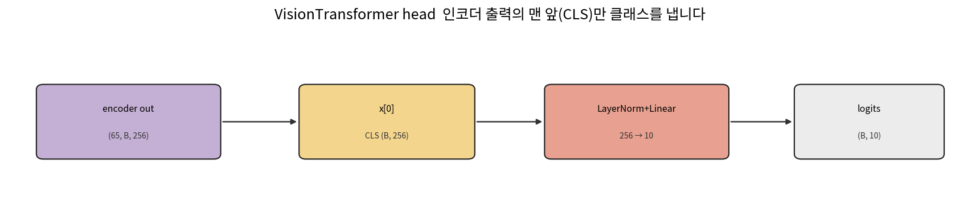

image (2, 3, 32, 32) logits (2, 10)
파라미터 3,195,146


In [6]:
class VisionTransformer(nn.Module):
    """이미지를 패치 시퀀스로 변환하여 분류하는 전체 Vision Transformer (ViT) 모델입니다."""
    def __init__(
        self,
        embed_dim,
        hidden_dim,
        num_channels,
        num_heads,
        num_layers,
        num_classes,
        patch_size,
        num_patches,
        dropout=0.0,
    ):
        super().__init__()
        self.patch_size = patch_size

        # 1. 평탄화된 패치 벡터(C * P^2 = 48)를 임베딩 차원(embed_dim = 256)으로 투영하는 선형 레이어
        self.input_layer = nn.Linear(num_channels * (patch_size**2), embed_dim)

        # 2. num_layers(6개)의 AttentionBlock을 순차적으로 연결한 트랜스포머 인코더
        self.transformer = nn.Sequential(
            *[AttentionBlock(embed_dim, hidden_dim, num_heads, dropout=dropout) for _ in range(num_layers)]
        )

        # 3. 최종 [CLS] 토큰 벡터를 입력받아 클래스별 로짓(Logits)을 출력하는 분류 헤드
        self.mlp_head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, num_classes),
        )
        self.dropout = nn.Dropout(dropout)

        # 4. 학습 가능한 [CLS] 토큰 파라미터 (1, 1, 256) 및 위치 임베딩 파라미터 (1, 1 + 64, 256)
        self.cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
        self.pos_embedding = nn.Parameter(torch.randn(1, 1 + num_patches, embed_dim))

    def forward(self, x):
        """
        Args:
            x (torch.Tensor): (B, 3, 32, 32) 형태의 입력 이미지 배치
        Returns:
            torch.Tensor: (B, 10) 형태의 클래스별 예측 로짓(Logits)
        """
        # Step 1: 이미지를 패치 시퀀스로 분할 및 평탄화 -> (B, 64, 48)
        x = img_to_patch(x, self.patch_size)
        batch, n_tokens, _ = x.shape

        # Step 2: 선형 투영을 통해 임베딩 차원으로 변환 -> (B, 64, 256)
        x = self.input_layer(x)

        # Step 3: 배치 크기(B)만큼 [CLS] 토큰을 복제한 뒤 패치 시퀀스의 맨 앞(dim=1)에 결합 -> (B, 65, 256)
        cls_token = self.cls_token.repeat(batch, 1, 1)
        x = torch.cat([cls_token, x], dim=1)

        # Step 4: 각 토큰 위치에 학습 가능한 위치 임베딩(Positional Embedding)을 더하고 드롭아웃 적용 -> (B, 65, 256)
        x = x + self.pos_embedding[:, : n_tokens + 1]
        x = self.dropout(x)

        # Step 5: nn.MultiheadAttention 입력 형식에 맞추기 위해 (Batch, Seq, Dim)을 (Seq, Batch, Dim)으로 전치 -> (65, B, 256)
        x = x.transpose(0, 1)

        # Step 6: 6개의 트랜스포머 인코더 블록을 통과 -> (65, B, 256)
        x = self.transformer(x)

        # Step 7: 시퀀스의 맨 앞(0번 인덱스)에 위치한 [CLS] 토큰의 출력 벡터만 추출 -> (B, 256)
        cls = x[0]

        # Step 8: 분류 헤드(LayerNorm + Linear)를 통과시켜 최종 10개 클래스 점수 반환 -> (B, 10)
        return self.mlp_head(cls)


# 인코더 출력에서 [CLS] 토큰만 추출하여 최종 로짓을 계산하는 분류 헤드 구조를 시각화합니다.
draw_blocks(
    "VisionTransformer head  인코더 출력의 맨 앞(CLS)만 클래스를 냅니다",
    [
        {"key": "enc", "cx": 2.2, "cy": 1.35, "title": "encoder out", "sub": "(65, B, 256)", "color": "#c5b0d5", "bw": 2.1},
        {"key": "cls", "cx": 5.2, "cy": 1.35, "title": "x[0]", "sub": "CLS (B, 256)", "color": "#f4d58d", "bw": 2.0},
        {"key": "lin", "cx": 8.1, "cy": 1.35, "title": "LayerNorm+Linear", "sub": "256 → 10", "color": "#e8a090", "bw": 2.1},
        {"key": "out", "cx": 10.8, "cy": 1.35, "title": "logits", "sub": "(B, 10)", "color": "#ececec", "bw": 1.7},
    ],
    [("enc", "cls"), ("cls", "lin"), ("lin", "out")],
    figsize=(12.4, 2.8),
)

# 설정한 하이퍼파라미터로 VisionTransformer 모델을 초기화하고 입출력 크기 및 총 파라미터 수를 확인합니다.
model = VisionTransformer(
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_channels=3,
    num_heads=N_HEADS,
    num_layers=N_LAYERS,
    num_classes=NUM_CLASSES,
    patch_size=PATCH,
    num_patches=N_PATCHES,
    dropout=DROPOUT,
)
x = torch.zeros(2, 3, IMG_SIZE, IMG_SIZE)
print("image", tuple(x.shape), "logits", tuple(model(x).shape))
print("파라미터", f"{sum(p.numel() for p in model.parameters()):,}")


## 4. 모델 학습 및 검증 루프

- **손실 함수(Loss Function)**: 다중 클래스 분류 문제의 표준인 **교차 엔트로피 손실(`nn.CrossEntropyLoss`)**을 사용합니다.
- **옵티마이저(Optimizer)**: 가중치 감쇠(Weight Decay)가 분리 적용되어 트랜스포머 학습에 효과적인 **`AdamW`**(`lr=3e-4`)를 사용합니다.
- **학습률 스케줄러(Learning Rate Scheduler)**: `MultiStepLR(optimizer, milestones=[8, 10], gamma=0.1)`을 사용하여 8번째 에폭과 10번째 에폭에서 학습률을 각각 $1/10$씩 감소시켜 후반부 수렴 정밀도를 높입니다.
- **`run_epoch` 통합 함수**: `train` 불리언 인자 하나로 학습 모드(`train=True`, 그래디언트 계산 및 가중치 업데이트 수행)와 평가 모드(`train=False`, 그래디언트 비활성화)를 모두 깔끔하게 처리합니다.


In [7]:
def run_epoch(model, loader, criterion, optimizer, train):
    """
    1 에폭(Epoch) 동안 모델의 학습(Train) 또는 평가(Validation/Test)를 수행합니다.

    Args:
        model (nn.Module): 학습/평가할 ViT 모델
        loader (DataLoader): 배치 데이터를 공급하는 데이터로더
        criterion (nn.Module): 손실 함수 (CrossEntropyLoss)
        optimizer (torch.optim.Optimizer | None): 가중치 업데이트용 옵티마이저 (평가 시 None 가능)
        train (bool): True이면 학습 모드(역전파 수행), False이면 평가 모드(순전파만 수행)
    Returns:
        tuple[float, float]: (전체 샘플 평균 손실, 전체 샘플 평균 정확도)
    """
    # train 값에 따라 Dropout 등의 동작을 학습 모드(True) 또는 평가 모드(False)로 전환합니다.
    model.train(train)
    total_loss, n_ok, n = 0.0, 0, 0

    for x, y in loader:
        # 미니배치 입력 이미지(x)와 정답 레이블(y)을 연산 장치(GPU/CPU)로 이동시킵니다.
        x, y = x.to(DEVICE), y.to(DEVICE)

        # 학습 모드일 때만 자동 미분(Autograd) 그래프를 생성하도록 제어합니다.
        with torch.set_grad_enabled(train):
            logits = model(x)
            loss = criterion(logits, y)

            # 학습 모드인 경우 그래디언트 초기화 -> 역전파 -> 파라미터 업데이트를 수행합니다.
            if train:
                optimizer.zero_grad(set_to_none=True)  # 메모리 효율을 위해 set_to_none=True 사용
                loss.backward()
                optimizer.step()

        # 가장 높은 로짓 값을 가진 클래스 인덱스를 예측값(pred)으로 선택합니다.
        pred = logits.argmax(1)
        bs = y.size(0)

        # 배치 크기를 곱해 전체 손실 합계와 정답 샘플 수(n_ok)를 누적합니다.
        total_loss += loss.item() * bs
        n_ok += int((pred == y).sum().item())
        n += bs

    # 전체 데이터 개수로 나누어 에폭 평균 손실과 평균 정확도를 반환합니다.
    return total_loss / max(n, 1), n_ok / max(n, 1)


# 모델을 GPU/CPU 장치로 이동시키고 손실 함수, 옵티마이저, 스케줄러를 초기화합니다.
model = model.to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[8, 10], gamma=0.1)

best_acc = -1.0
best_path = Path("vit_cifar10_best.pt")

# 총 12 에폭 동안 학습과 검증을 반복하며 최고 검증 정확도(best_acc) 갱신 시 가중치를 저장합니다.
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, True)
    va_loss, va_acc = run_epoch(model, val_loader, criterion, optimizer, False)
    scheduler.step()  # 에폭 종료 후 학습률 스케줄러를 1스텝 진행합니다.

    print(
        f"epoch {epoch:02d}  train_loss {tr_loss:.4f}  train_acc {tr_acc:.4f}  "
        f"val_loss {va_loss:.4f}  val_acc {va_acc:.4f}"
    )
    # 검증 정확도가 이전 최고 기록을 경신하면 모델의 상태 사전(state_dict)을 파일로 저장합니다.
    if va_acc > best_acc:
        best_acc = va_acc
        torch.save(model.state_dict(), best_path)

print("best val_acc", round(best_acc, 4), "saved", best_path)


epoch 01  train_loss 1.7567  train_acc 0.3540  val_loss 1.4586  val_acc 0.4746
epoch 02  train_loss 1.4494  train_acc 0.4786  val_loss 1.3214  val_acc 0.5262
epoch 03  train_loss 1.3340  train_acc 0.5198  val_loss 1.2302  val_acc 0.5592
epoch 04  train_loss 1.2562  train_acc 0.5503  val_loss 1.1582  val_acc 0.5880
epoch 05  train_loss 1.2032  train_acc 0.5683  val_loss 1.1208  val_acc 0.6036
epoch 06  train_loss 1.1498  train_acc 0.5885  val_loss 1.1082  val_acc 0.5984
epoch 07  train_loss 1.1198  train_acc 0.5994  val_loss 1.0781  val_acc 0.6160
epoch 08  train_loss 1.0801  train_acc 0.6122  val_loss 1.0701  val_acc 0.6234
epoch 09  train_loss 0.9964  train_acc 0.6455  val_loss 0.9911  val_acc 0.6464
epoch 10  train_loss 0.9790  train_acc 0.6503  val_loss 0.9764  val_acc 0.6498
epoch 11  train_loss 0.9596  train_acc 0.6586  val_loss 0.9775  val_acc 0.6506
epoch 12  train_loss 0.9603  train_acc 0.6590  val_loss 0.9750  val_acc 0.6530
best val_acc 0.653 saved vit_cifar10_best.pt


## 5. 최종 테스트 평가 및 예측 결과 시각화

검증 데이터셋에서 가장 높은 정확도를 기록했던 최적 가중치 파일(`vit_cifar10_best.pt`)을 모델에 다시 로드한 뒤, 학습 과정에서 한 번도 보지 못한 **테스트 데이터셋(10,000장)**에 대한 최종 손실(`test_loss`)과 정확도(`test_acc`)를 측정합니다.
아울러 테스트 배치에서 앞쪽 16장의 이미지를 추출하여 모델이 예측한 클래스 레이블과 실제 정답 레이블을 나란히 비교해 봅니다.


test_loss 0.9653 test_acc 0.6596


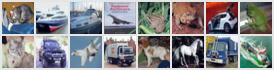

정답 ['cat', 'ship', 'ship', 'airplane', 'frog', 'frog', 'automobile', 'frog', 'cat', 'automobile', 'airplane', 'truck', 'dog', 'horse', 'truck', 'ship']
예측 ['cat', 'ship', 'airplane', 'airplane', 'frog', 'frog', 'automobile', 'frog', 'dog', 'automobile', 'airplane', 'truck', 'cat', 'horse', 'truck', 'deer']


In [8]:
# 저장해 둔 최고 성능 모델의 가중치(state_dict)를 로드합니다.
model.load_state_dict(torch.load(best_path, map_location=DEVICE))

# 테스트 데이터로더(test_loader)에 대해 평가 모드(train=False)로 최종 성능을 측정합니다.
te_loss, te_acc = run_epoch(model, test_loader, criterion, None, False)
print("test_loss", round(te_loss, 4), "test_acc", round(te_acc, 4))

# 모델을 평가 모드로 전환하고 테스트 배치에서 첫 16장의 샘플 이미지를 가져와 추론을 수행합니다.
model.eval()
x, y = next(iter(test_loader))
x = x[:16].to(DEVICE)
with torch.no_grad():
    # 각 이미지에 대해 가장 높은 점수를 얻은 클래스 인덱스를 추출합니다.
    pred = model(x).argmax(1).cpu()

# 16장의 테스트 이미지를 8열 2행 그리드로 시각화하고 실제 정답과 모델 예측 결과를 비교 출력합니다.
grid = torchvision.utils.make_grid(x.cpu(), nrow=8, normalize=True, pad_value=0.9)
show_img(transforms.functional.to_pil_image(grid), width=980)
print("정답", [CLASSES[int(v)] for v in y[:16]])
print("예측", [CLASSES[int(v)] for v in pred])
